In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
data = {
    'X': [-2, -1, 0, 1, 2],
    'Y': [-11, -2, 1, 4, 13]
}

df = pd.DataFrame(data)

print(df)

   X   Y
0 -2 -11
1 -1  -2
2  0   1
3  1   4
4  2  13


In [3]:
X = df[['X']]
y = df['Y']

In [4]:
poly = PolynomialFeatures(degree=3)

X_poly = poly.fit_transform(X)

print("Polynomial Features:")
print(X_poly)

Polynomial Features:
[[ 1. -2.  4. -8.]
 [ 1. -1.  1. -1.]
 [ 1.  0.  0.  0.]
 [ 1.  1.  1.  1.]
 [ 1.  2.  4.  8.]]


In [5]:
model = LinearRegression()

model.fit(X_poly, y)

y_pred = model.predict(X_poly)

print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

Intercept: 1.0000000000000013
Coefficients: [ 0.00000000e+00  2.00000000e+00 -6.66133815e-16  1.00000000e+00]


In [6]:
b0 = model.intercept_
b1 = model.coef_[1]
b2 = model.coef_[2]
b3 = model.coef_[3]

print("Polynomial Equation:")

print(f"Y = {b0:.2f} + ({b1:.2f})X + ({b2:.2f})X² + ({b3:.2f})X³")

Polynomial Equation:
Y = 1.00 + (2.00)X + (-0.00)X² + (1.00)X³


In [7]:
mse = mean_squared_error(y, y_pred)

r2 = r2_score(y, y_pred)

print("MSE:", mse)
print("R2 Score:", r2)

MSE: 1.2109014895142531e-29
R2 Score: 1.0


In [8]:
comparison = pd.DataFrame({
    'Actual Y': y,
    'Predicted Y': y_pred
})

print(comparison)

   Actual Y  Predicted Y
0       -11        -11.0
1        -2         -2.0
2         1          1.0
3         4          4.0
4        13         13.0


C:\Users\User\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


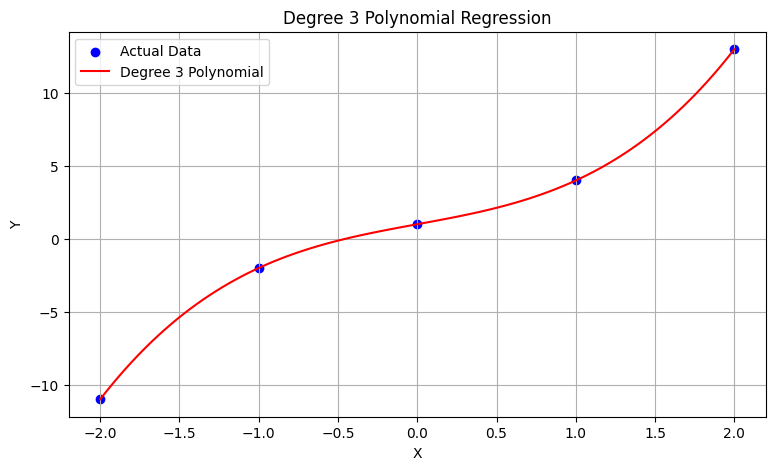

In [9]:
X_range = np.linspace(-2, 2, 100).reshape(-1, 1)

X_range_poly = poly.transform(X_range)

y_range_pred = model.predict(X_range_poly)

plt.figure(figsize=(9, 5))

plt.scatter(X, y, color='blue', label='Actual Data')

plt.plot(
    X_range,
    y_range_pred,
    color='red',
    label='Degree 3 Polynomial'
)

plt.xlabel('X')
plt.ylabel('Y')

plt.title('Degree 3 Polynomial Regression')

plt.legend()
plt.grid()

plt.show()

In [10]:
new_X = pd.DataFrame({
    'X': [3, 4, 5]
})

new_X_poly = poly.transform(new_X)

predictions = model.predict(new_X_poly)

result = pd.DataFrame({
    'X': new_X['X'],
    'Predicted Y': predictions
})

print(result)

   X  Predicted Y
0  3         34.0
1  4         73.0
2  5        136.0
